In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("customers.csv")

In [3]:
df.head()

,CustomerID,Age,Annual Income,Spending Score
0,C0001,23,87726,92
1,C0002,26,18860,28
2,C0003,41,61435,100
3,C0004,38,111119,74
4,C0005,33,121280,81


In [4]:
features = ["Age", "Annual Income", "Spending Score"]

In [5]:
X = df[features].dropna()

In [9]:
X.head()

,Age,Annual Income,Spending Score
0,23,87726,92
1,26,18860,28
2,41,61435,100
3,38,111119,74
4,33,121280,81


In [6]:
from sklearn.preprocessing import StandardScaler

In [7]:
scaler = StandardScaler()

In [8]:
X_scaled = scaler.fit_transform(X)

In [12]:
X_scaled

array([[-1.07317116,  0.35173686,  1.34489473],
       [-0.81712587, -1.51561367, -0.9570218 ],
       [ 0.46310058, -0.36116229,  1.6326343 ],
       ...,
       [ 0.71914587,  0.94112395,  0.26587136],
       [ 0.29240372,  0.78184627, -1.10089158],
       [ 1.23123645,  1.60394038, -0.41751011]], shape=(500, 3))

In [16]:
from sklearn.cluster import KMeans

In [21]:
#Apply elbow method

wcss = []

k_values = range(1,11)

for k in k_values:
    model = KMeans(
        n_clusters = k,
        init = "k-means++",
        n_init = 10,
        random_state = 1
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

Text(0.5, 1.0, 'Elbow method for optimal K')

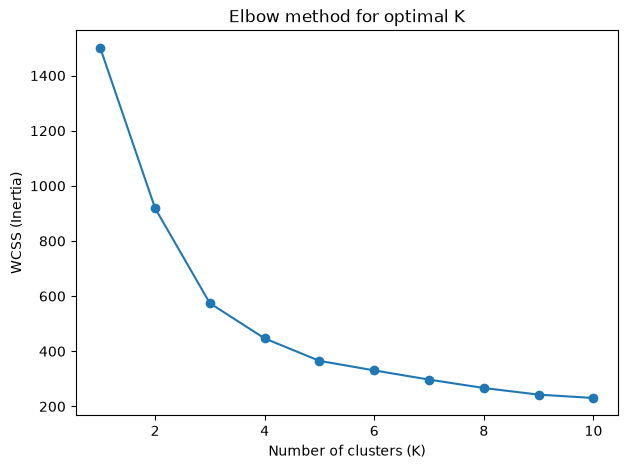

In [25]:
plt.figure(figsize=(7,5))

plt.plot(
    k_values,
    wcss,
    marker = 'o',
    linestyle = '-'
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow method for optimal K")

In [26]:
optimal_K = 4

final_model = KMeans(
    n_clusters=optimal_K,
    init="k-means++",
    n_init=10,
    random_state=1
)

In [27]:
#predicting the label

labels = final_model.fit_predict(X_scaled)

labels

array([1, 2, 0, 0, 0, 2, 3, 0, 0, 0, 1, 1, 2, 0, 2, 2, 1, 0, 1, 2, 2, 0,
       1, 2, 3, 0, 3, 1, 2, 2, 0, 0, 1, 1, 1, 2, 2, 2, 2, 0, 3, 1, 0, 3,
       1, 0, 1, 3, 2, 3, 1, 3, 2, 0, 3, 2, 2, 1, 0, 0, 0, 0, 0, 2, 1, 3,
       0, 1, 2, 2, 0, 2, 1, 1, 1, 2, 1, 1, 1, 2, 0, 1, 0, 0, 2, 0, 2, 1,
       3, 1, 3, 1, 3, 2, 3, 1, 1, 1, 2, 2, 0, 3, 3, 0, 2, 0, 3, 3, 3, 0,
       0, 3, 0, 2, 3, 2, 3, 3, 2, 2, 0, 3, 1, 2, 2, 3, 3, 0, 1, 1, 2, 1,
       1, 1, 1, 2, 2, 2, 0, 2, 0, 2, 3, 1, 0, 1, 0, 3, 1, 2, 1, 3, 2, 2,
       1, 0, 2, 0, 1, 0, 3, 2, 3, 0, 2, 3, 2, 2, 0, 3, 1, 1, 0, 1, 0, 0,
       0, 1, 3, 2, 1, 2, 0, 2, 0, 0, 2, 3, 1, 1, 1, 0, 1, 1, 3, 0, 3, 2,
       0, 0, 1, 2, 1, 2, 0, 2, 0, 1, 2, 1, 2, 1, 2, 2, 2, 1, 2, 3, 0, 0,
       3, 0, 2, 3, 2, 3, 3, 0, 2, 1, 2, 0, 1, 1, 2, 2, 0, 3, 2, 3, 2, 2,
       3, 0, 2, 1, 3, 2, 0, 2, 3, 1, 0, 2, 0, 1, 3, 3, 2, 1, 3, 2, 1, 1,
       2, 3, 0, 0, 2, 0, 2, 1, 1, 1, 2, 1, 2, 2, 2, 0, 1, 1, 2, 0, 0, 3,
       3, 0, 2, 1, 3, 1, 2, 2, 2, 3, 3, 3, 2, 1, 1,

In [28]:
#Attach Cluster labels to retained rows

df_clustered = df.loc[X.index].copy()
df_clustered["Cluster"] = labels

In [29]:
df_clustered

,CustomerID,Age,Annual Income,Spending Score,Cluster
0,C0001,23,87726,92,1
1,C0002,26,18860,28,2
2,C0003,41,61435,100,0
3,C0004,38,111119,74,0
4,C0005,33,121280,81,0
...,...,...,...,...,...
495,C0496,39,46183,74,1
496,C0497,19,21473,29,2
497,C0498,44,109462,62,0
498,C0499,39,103588,24,3


In [30]:
#evaluate Clustering
final_model.inertia_

446.62457296706157

In [33]:
from sklearn.metrics import silhouette_score

In [34]:
silhouette_score(X_scaled,labels)

0.36679324725475076

In [35]:
#understand the cluster features
df_clustered.groupby("Cluster")[features].mean()

,Age,Annual Income,Spending Score
Cluster,,,
0,42.238938,98921.884956,77.796460
1,28.041379,66372.958621,78.827586
2,28.040268,37545.483221,31.409396
3,51.290323,118071.193548,25.838710


Text(0.5, 1.0, 'Customer segmentation using K-means')

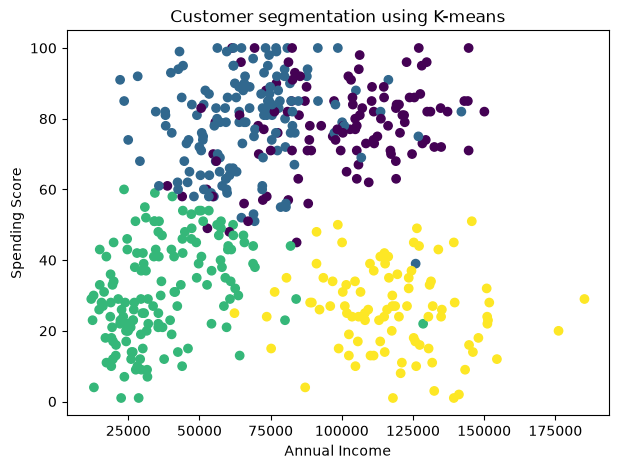

In [37]:
#visialize the customer segments
plt.figure(figsize=(7,5))

plt.scatter(
    df_clustered["Annual Income"],
    df_clustered["Spending Score"],
    c=labels,
    cmap='viridis'
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer segmentation using K-means")
